<a href="https://colab.research.google.com/github/email81227/llm-study/blob/master/AI_%E5%AF%A6%E6%88%B0%E5%B7%A5%E4%BD%9C%E5%9D%8A(python%E8%88%87pytorch).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 從零開始 Python 程式設計實作

好，接下來我們正式進到 Colab 實作。

前面 PPT 已經介紹過 Python 的一些基本語法，所以這裡不會重新把每個語法再講一次，我們會先快速操作幾個等等會用到的概念。

前面這幾個部分大家先跟著執行、觀察結果就可以；到了 **Class** 之後，我們會開始比較仔細地看程式結構，因為等等建立 PyTorch Model 時會直接用到。

**實作主線：Python 基礎 → DNA 規則式練習 → Tensor → PyTorch Model → MNIST 手寫數字辨識**


### Python基礎

In [ ]:
import this

The Zen of Python, by Tim Peters

Beautiful is better than ugly.
Explicit is better than implicit.
Simple is better than complex.
Complex is better than complicated.
Flat is better than nested.
Sparse is better than dense.
Readability counts.
Special cases aren't special enough to break the rules.
Although practicality beats purity.
Errors should never pass silently.
Unless explicitly silenced.
In the face of ambiguity, refuse the temptation to guess.
There should be one-- and preferably only one --obvious way to do it.
Although that way may not be obvious at first unless you're Dutch.
Now is better than never.
Although never is often better than *right* now.
If the implementation is hard to explain, it's a bad idea.
If the implementation is easy to explain, it may be a good idea.
Namespaces are one honking great idea -- let's do more of those!


### Python 快速暖身

前面幾個 Cell 只需要先掌握它們的用途，不需要逐行記語法：

- `print()`：把結果輸出到畫面上，後面也會用來查看資料、Loss 或 Accuracy。
- Boolean 與 `if / else`：根據條件的 `True / False` 決定程式執行哪一條路徑。
- `type()`：查看資料型態。
- List：把一組資料放在一起。
- `for`：重複執行一段操作；後面的 DNA 練習與模型訓練都會再次用到。

先執行並觀察結果即可，**Class 開始再進入比較完整的程式結構說明**。


In [ ]:
# 1. Print, String and Function
print("Hello, world!")

Hello, world!


In [ ]:
# 2. Boolean and Conditional Statements

chicken_crossed_road = True

# Conditional check
if chicken_crossed_road:
    print("They get to the other side!")
else:
    print("Why did the chicken cross the road?")


They get to the other side!


In [ ]:
# 3. Type, List　and Loop

# Type
print(type(chicken_crossed_road))

# List
shopping_list = ["eggs", "milk", "bread", "cheese"]
print(type(shopping_list))

# Loop through the shopping list
for item in shopping_list:
  print("Don't forget to buy", item)

<class 'bool'>
<class 'list'>
Don't forget to buy eggs
Don't forget to buy milk
Don't forget to buy bread
Don't forget to buy cheese


In [ ]:
# 練習：從 shopping_list 輸出 bread
shopping_list[2]


'bread'

In [ ]:
shopping_list[-1] #填入正確的數字

'cheese'

### 4. Class and Object — 從這裡開始仔細看

前面的 `print`、`if`、`for` 都是一般 Python 很常見的語法；從 **Class** 開始，我們要稍微仔細一點，因為等等建立 PyTorch Model 時會直接看到同樣的結構。

可以先把 Class 想成「建立物件的設計圖」：

- `class`：定義一種類型或物件的設計方式。
- `__init__()`：建立物件時先準備它需要的資料。
- `self`：代表「這個物件自己」。之後在 PyTorch 會看到 `self.fc1`、`self.relu`、`self.fc2`。
- method：寫在 Class 裡面的 function。
- Object：依照 Class 實際建立出來的物件。

下面先用 `Dog` 當例子。等等會再把這個概念直接接到 `SimpleMLP(nn.Module)`。


In [ ]:
# 4. Class and Object

# Define a class for a dog
class Dog:
  def __init__(self, name, breed):
    self.name = name
    self.breed = breed

  def bark(self):
    print("Woof!")

# Create a dog object
my_dog = Dog("Buddy", "Golden Retriever")

# Access object attributes
print(my_dog.name)  # Output: Buddy
print(my_dog.breed)  # Output: Golden Retriever

# Call object method
my_dog.bark()  # Output: Woof!

Buddy
Golden Retriever
Woof!


In [ ]:
# 5. Modules and Packages
import math

# Check modules information
# help('math') # ctrl + /

# Calculate the square root of a number
number = 16
square_root = math.sqrt(number)
print("The square root of", number, "is", square_root)


The square root of 16 is 4.0


In [ ]:
# 6. File I/O

# Write to a file
with open("my_file.txt", "w") as f:
  f.write("Hello, file!\n")
  f.write("This is some text.\n")

# Read from a file
with open("my_file.txt", "r") as f:
  content = f.read()
  print(content)


Hello, file!
This is some text.



### 小練習：計算隨機產生的 DNA 序列中可以產生多少氫鍵

Class 先看到這裡。等等進到真正的 PyTorch Model，我們會把 `Class`、`__init__`、`self` 再接回來。

在那之前，先把前面快速帶過的 **Function、for、if** 組合成一個完整的小練習。

這裡的規則是：

- A、T：各計算 2 個氫鍵
- C、G：各計算 3 個氫鍵

這也對應到前面 PPT 的「傳統程式設計」概念：**規則是由人先定義，再寫進程式中**。等等進入 MNIST 後，就會改成讓模型從資料中學習，而不是由我們直接寫出「什麼樣子是 7、什麼樣子是 8」的判斷規則。


In [ ]:
import random

def generate_dna(length):
  bases = "ATCG"
  dna_sequence = "".join(random.choice(bases) for _ in range(length))
  return dna_sequence

# Generate a DNA sequence of length 10
dna_sequence = generate_dna(10)
print(dna_sequence)


CATCCACCTG


In [ ]:
dna_seq10 = "TATCTTGAAA"
dna_seq100 = "CTTTCGACCACTTCAAGTTTATGCCAAGATGGCCTACTTTTTTGCGGGCCAACGATGACTTCACTATTTACAAGTGAAGTGAAAAATAAGTCCCGAAGAC"
dna_seq1000 = "CTCCGACCACAACAACTTGTCAAAGATAAAAGCGTGAATGCGAGGCATAGTCCTTGGACACCTAACAATCTGAAAACGCTCCTCGACTTGAGATTTAGAAGTCGTAGTCAACTCTGGCCACGCTATACTGCGACGATCTGAATTTACCGTAGCCAGGTAAAGAACGGGGTCATGCGACCCGAGGAGTTGTGCTAATTGCTACGGTATTATCCGCTTCCTGTGACTGTTTCAAAAGCATTGATTACCTGTTACTTCCAGCTGCTAAGCCGCGCGAATAGTGTTAGCTACGTGTAAGCCTCGATATCCGTGAACCCAGTCGCGCGAGTTCTATTGTCATCGAACGGTGCATTACTCGGGTCCTCCGACTCGTGGCTCTTAAGTCTGGGCGTGCTCTCTCGTATAGTGGTTTGAGGCCTGACCAAAGATCCTGCGTATCGACAACAACCTAAAGACGTGTTCCCAATCCTATATCGGTCTGCCATGAACGCCCATGGCCAGACTGTAAGTTATAGGGACCCTTAGATCCGCTGGTGCCCCAGTCCGTTTCGCTTCGCGTGCGTCATGGCCTTCTGACAATGTTGGGGCGCTCGGCAATTAAGCATCAATAGGAGTCGCCAAGATGTACTTCCGTCTTGCGCAAGACGACCACTCCGTGTTACACCAGTGAAGCTACCTCATGATGGAGAATTACCGCAGTAGTCGACGGAACCTGCACGTGGAGGATCAACCTTCAGTCTCCTGGAGTCAGGTCCAGTGGACAGGCGGTGGTATGGGTTATAGGTAGGAGACCATCCCAGAACCGACCGTTTACCTCGGAAAGATATAAAAGTATATCCAGTGTCCGAGCTCCTTCGATCGGCTTACTTGCGGTTGGTCGTGATTTGCAGGCACCAATCACACTAACTGGTAAGAACAGAAGGGTGCAACGATTCCTGCCGAGCCCCGGGAGGGTCTATCCCACCAGTCTGGGCTACCGACCATAGCTGAGGACTAAAACAGC"

In [ ]:
def count_hydrogen_bonds(dna_sequence):
  """
  Calculates the number of hydrogen bonds in a DNA sequence.

  Args:
    dna_sequence: A string representing the DNA sequence.

  Returns:
    The number of hydrogen bonds in the sequence.
  """
  bonds = 0
  ### 請在這邊開始練習

  ### 請在這邊結束練習
  return bonds

# Calculate and print the number of hydrogen bonds
num_bonds = count_hydrogen_bonds(dna_sequence)
print("Number of hydrogen bonds:", num_bonds)


Number of hydrogen bonds: 0


###小練習解答: 計算氫鍵數量

In [ ]:
def count_hydrogen_bonds(dna_sequence):
  """
  Calculates the number of hydrogen bonds in a DNA sequence.

  Args:
    dna_sequence: A string representing the DNA sequence.

  Returns:
    The number of hydrogen bonds in the sequence.
  """
  bonds = 0
  for base in dna_sequence:
    if base in "AT":
      bonds += 2
    elif base in "CG":
      bonds += 3
  return bonds

# Calculate and print the number of hydrogen bonds
num_bonds = count_hydrogen_bonds(dna_sequence)
print("Number of hydrogen bonds:", num_bonds)


Number of hydrogen bonds: 26


In [ ]:
num_bonds = count_hydrogen_bonds(dna_seq10)
print("Number of hydrogen bonds(10):", num_bonds)
num_bonds = count_hydrogen_bonds(dna_seq100)
print("Number of hydrogen bonds(100):", num_bonds)
num_bonds = count_hydrogen_bonds(dna_seq1000)
print("Number of hydrogen bonds(1000):", num_bonds)

Number of hydrogen bonds(10): 22
Number of hydrogen bonds(100): 242
Number of hydrogen bonds(1000): 2516


### PyTorch 基礎：Tensor 操作

接下來正式從一般 Python 進到 PyTorch。

PyTorch 處理數值資料時，最基本的資料結構就是 **Tensor**。這一段先特別注意兩件事：

- `dtype`：Tensor 裡的數值型態。
- `shape`：Tensor 每一個維度的大小。

Tensor 的形狀不相容是初學 PyTorch 很常見的錯誤，因此之後遇到尺寸問題，可以先檢查 `x.shape`；需要時也可以查看 `x.dtype` 與 `x.device`。

後面的 MNIST 圖片也會轉成 Tensor，再送進模型中。


In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
import time
print(torch.cuda.is_available()) #能不能用GPU
print(torch.__version__)     #版本編號

True
2.5.1+cu121


In [ ]:
# 1. tensor

# Create a tensor from a list
x_data = [1, 2, 3]
x_tensor = torch.Tensor(x_data)
print(x_tensor)

# Create a tensor from a NumPy array
import numpy as np
np_array = np.array([4, 5, 6])
tensor_from_numpy = torch.Tensor(np_array)
print(tensor_from_numpy)

# Create a tensor with random values
random_tensor = torch.rand(2, 3)
print(random_tensor)


tensor([1., 2., 3.])
tensor([4., 5., 6.])
tensor([[0.8230, 0.3418, 0.4727],
        [0.4177, 0.1046, 0.6274]])


In [ ]:
x_tensor.dtype

torch.float32

In [ ]:
x = x_tensor.to(int)
x.dtype

torch.int64

In [ ]:
x_tensor.shape

torch.Size([3])

In [ ]:
random_tensor.shape

torch.Size([2, 3])

### 手寫數字辨識：架設第一個 MLP

接下來把剛才 Python 的 Class 直接接到真正的 PyTorch Model。

當看到：

```python
class SimpleMLP(nn.Module):
```

可以拆成兩件事：

1. `SimpleMLP` 是我們自己建立的模型 Class。
2. `nn.Module` 是 PyTorch 提供的模型基礎類別；`SimpleMLP` 透過 **Inheritance（繼承）** 沿用它的模型與參數管理功能。

PyTorch Model 裡先找兩個最重要的區塊：

| 區塊 | 可以怎麼理解 | 功能 |
|---|---|---|
| `__init__()` | 模型有哪些零件 | 宣告 Layer 與元件 |
| `forward()` | 資料要怎麼走 | 定義資料通過各 Layer 的順序 |

這次刻意使用簡單的 MLP，讓完整流程比較容易看清楚：

**28 × 28 image → Flatten → 784 → Linear(128) → ReLU → Linear(10)**

其中 10 個輸出對應 MNIST 的數字 `0～9`。實際應用時可以增加 Hidden Layer、調整神經元數量，或改用 CNN；這裡的重點是先理解 PyTorch 建模與訓練的完整結構。


In [ ]:
import torchvision
import torchvision.transforms as transforms

# Download the MNIST training dataset
trainset = torchvision.datasets.MNIST(root='./data', train=True, download=True)

# Download the MNIST test dataset
testset = torchvision.datasets.MNIST(root='./data', train=False, download=True)


In [ ]:
# help(trainset)

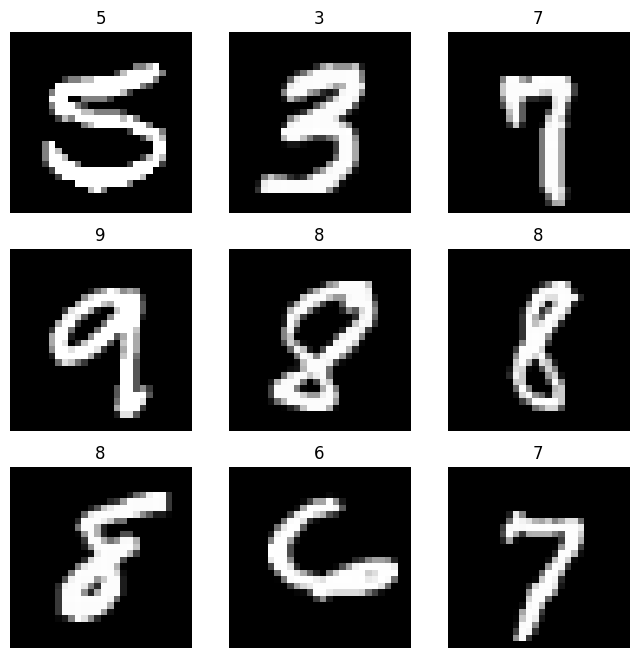

In [ ]:
# prompt: 幫我呈現出MNIST資料的九張影像

import matplotlib.pyplot as plt

figure = plt.figure(figsize=(8, 8))
cols, rows = 3, 3
for i in range(1, cols * rows + 1):
    sample_idx = torch.randint(len(trainset), size=(1,)).item()
    img, label = trainset[sample_idx]
    figure.add_subplot(rows, cols, i)
    plt.title(label)
    plt.axis("off")
    plt.imshow(img, cmap="gray")
plt.show()


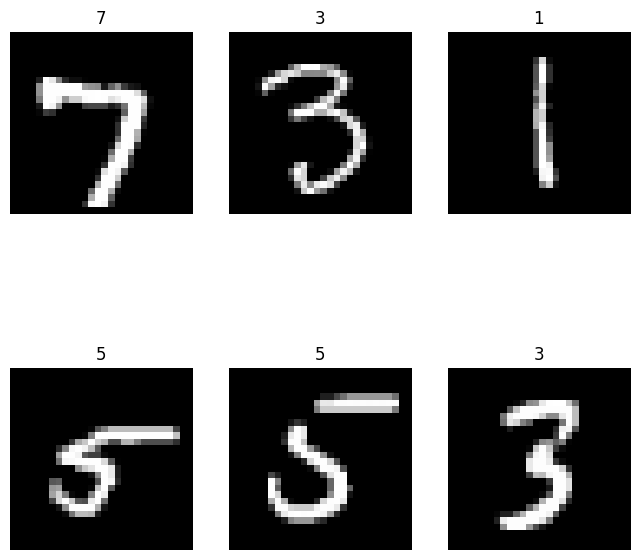

In [ ]:
# prompt: 幫我呈現出測試集裡面的六張影像

figure = plt.figure(figsize=(8, 8))
cols, rows = 3, 2
for i in range(1, cols * rows + 1):
    sample_idx = torch.randint(len(testset), size=(1,)).item()
    img, label = testset[sample_idx]
    figure.add_subplot(rows, cols, i)
    plt.title(label)
    plt.axis("off")
    plt.imshow(img, cmap="gray")
plt.show()


In [ ]:
trainset.data.shape

torch.Size([60000, 28, 28])

In [ ]:
testset

Dataset MNIST
    Number of datapoints: 10000
    Root location: ./data
    Split: Test

In [ ]:
# 定義數據集的轉換
transform = transforms.Compose([
    transforms.ToTensor(),  # 轉換圖像為Tensor
])

# 加載MNIST數據集
trainset = torchvision.datasets.MNIST(root='./data', train=True, download=True, transform=transform)
testset = torchvision.datasets.MNIST(root='./data', train=False, download=True, transform=transform)


In [ ]:
testset

Dataset MNIST
    Number of datapoints: 10000
    Root location: ./data
    Split: Test
    StandardTransform
Transform: Compose(
               ToTensor()
           )

In [ ]:
# 超參數
batch_size = 256
learning_rate = 0.001
num_epochs = 10

# 定義模型
class SimpleMLP(nn.Module):
    def __init__(self):
        super().__init__()
        self.flatten = nn.Flatten()
        self.fc1 = nn.Linear(28 * 28, 128)
        self.relu = nn.ReLU()
        self.fc2 = nn.Linear(128, 10)

    def forward(self, x):
        x = self.flatten(x)
        x = self.fc1(x)
        x = self.relu(x)
        x = self.fc2(x)
        return x

# 檢查是否有可用的 GPU
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# 初始化模型和優化器
model = SimpleMLP().to(device)
optimizer = optim.Adam(model.parameters(), lr=learning_rate)

# 定義損失函數
criterion = nn.CrossEntropyLoss()

print(device)


cuda


### 模型訓練：把前面的概念串起來

後面看到完整 Training Loop 時，先不要被程式碼數量嚇到。可以先找出四個角色：

| 角色 | 常見名稱 | 功能 |
|---|---|---|
| Data / Tensor | `images`, `labels` | 模型的輸入資料與正確答案 |
| Model | `model` | 將 input 轉成 output |
| Loss | `criterion`, `loss` | 衡量預測和正確答案差多少 |
| Optimizer | `optimizer` | 根據梯度更新模型參數 |

真正的核心可以先看這五個步驟：

```python
optimizer.zero_grad()
outputs = model(images)
loss = criterion(outputs, labels)
loss.backward()
optimizer.step()
```

也就是：**清除舊梯度 → Forward → 計算 Loss → Backpropagation → 更新參數**。

外面的 `for epoch ...` 與 DataLoader，則是讓這個流程對不同 Batch 重複執行。這也是前面 Python `for` 迴圈真正進入模型訓練的地方。


In [ ]:
# 創建數據加載器
train_loader = torch.utils.data.DataLoader(trainset, batch_size=batch_size, shuffle=True)
test_loader = torch.utils.data.DataLoader(testset, batch_size=batch_size, shuffle=False)

# 訓練迴圈
best_accuracy = 0.0
for epoch in range(num_epochs):
    start_time = time.time()  # 記錄訓練開始時間

    # 訓練模式
    model.train()
    running_loss = 0.0
    for batch_idx, (images, labels) in enumerate(train_loader):
        images, labels = images.to(device), labels.to(device)

        # 清除梯度
        optimizer.zero_grad()

        # 前向傳播
        outputs = model(images)

        # 計算損失
        loss = criterion(outputs, labels)
        running_loss += loss.item()

        # 反向傳播和優化
        loss.backward()
        optimizer.step()

        if (batch_idx + 1) % 100 == 0:  # 每100個batch打印一次
            print(f'Epoch [{epoch+1}/{num_epochs}], Step [{batch_idx+1}/{len(train_loader)}], Loss: {loss.item():.4f}')

    train_time = time.time() - start_time  # 記錄訓練結束時間

    # 評估模式
    model.eval()
    with torch.no_grad():
        start_eval_time = time.time()  # 記錄評估開始時間

        correct = 0
        total = 0
        for images, labels in test_loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            _, predicted = torch.max(outputs.data, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()

        eval_time = time.time() - start_eval_time  # 記錄評估結束時間

        accuracy = 100 * correct / total

        if best_accuracy < accuracy:
            best_accuracy = accuracy
            torch.save(model.state_dict(), 'best_model.pth')

        print(f'Epoch [{epoch+1}/{num_epochs}], Loss: {running_loss/len(train_loader):.4f}, Test Accuracy: {accuracy:.2f}%, Train Time: {train_time:.2f}s, Eval Time: {eval_time:.2f}s')

Epoch [1/10], Step [100/235], Loss: 0.4321
Epoch [1/10], Step [200/235], Loss: 0.3028
Epoch [1/10], Loss: 0.5301, Test Accuracy: 92.09%, Train Time: 5.52s, Eval Time: 0.86s
Epoch [2/10], Step [100/235], Loss: 0.2339
Epoch [2/10], Step [200/235], Loss: 0.2039
Epoch [2/10], Loss: 0.2374, Test Accuracy: 94.17%, Train Time: 5.45s, Eval Time: 0.84s
Epoch [3/10], Step [100/235], Loss: 0.1827
Epoch [3/10], Step [200/235], Loss: 0.1734
Epoch [3/10], Loss: 0.1768, Test Accuracy: 95.37%, Train Time: 5.49s, Eval Time: 0.83s
Epoch [4/10], Step [100/235], Loss: 0.1240
Epoch [4/10], Step [200/235], Loss: 0.1402
Epoch [4/10], Loss: 0.1408, Test Accuracy: 96.17%, Train Time: 5.55s, Eval Time: 0.82s
Epoch [5/10], Step [100/235], Loss: 0.0920
Epoch [5/10], Step [200/235], Loss: 0.1678
Epoch [5/10], Loss: 0.1161, Test Accuracy: 96.54%, Train Time: 5.59s, Eval Time: 0.85s
Epoch [6/10], Step [100/235], Loss: 0.0864
Epoch [6/10], Step [200/235], Loss: 0.0709
Epoch [6/10], Loss: 0.0990, Test Accuracy: 96.91%

### Result Interpretation：不只看 Accuracy

模型訓練完成之後，不只看一個整體 Accuracy，也可以直接查看模型實際預測的結果。

下面會：

1. 載入剛才儲存的最佳模型。
2. 取一張 Test Image 做 Prediction。
3. 比較 `predicted`（模型預測）與 `labels`（正確答案）。
4. 最後再找一筆 **Error Case**，觀察模型實際在哪一類影像上判斷錯誤。

這樣可以從 **整體指標 → 單筆預測 → 錯誤案例** 三個層次理解模型結果。


In [ ]:
# 假設你已經定義了模型的類別
m = SimpleMLP()
m.load_state_dict(torch.load('best_model.pth', weights_only=True))
m.to(device)  # 如果使用GPU，將模型移到GPU
m.eval()  # 切換到評估模式

test_loader = torch.utils.data.DataLoader(testset, batch_size=1, shuffle=False)

for images, labels in test_loader:
  images, labels = images.to(device), labels.to(device)
  outputs = m(images)
  _, predicted = torch.max(outputs.data, 1)
  print(predicted)
  print(labels)
  break

tensor([7], device='cuda:0')
tensor([7], device='cuda:0')


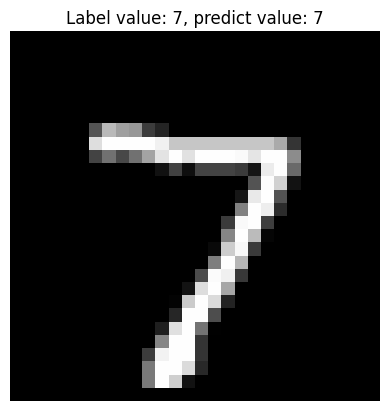

In [ ]:
plt.title(f"Label value: {labels.item()}, predict value: {predicted.item()}")
plt.axis("off")
plt.imshow(images.squeeze().cpu().numpy(), cmap="gray")
plt.show()

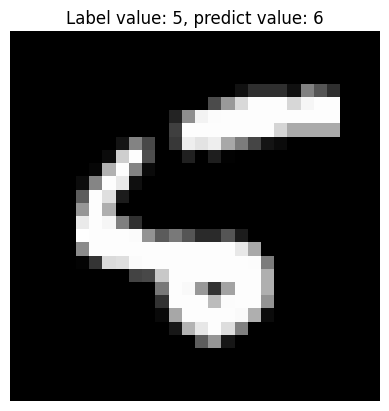

In [ ]:
# 模型預測錯誤的案例
for images, labels in test_loader:
  images, labels = images.to(device), labels.to(device)
  outputs = m(images)
  _, predicted = torch.max(outputs.data, 1)
  if predicted != labels:
    plt.title(f"Label value: {labels.item()}, predict value: {predicted.item()}")
    plt.axis("off")
    plt.imshow(images.squeeze().cpu().numpy(), cmap="gray")
    plt.show()
    break